# Importing và khai báo biến

In [14]:
from pathlib import Path
from types import SimpleNamespace
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

get_ipython().run_line_magic("matplotlib", "inline")

folders = [Path.cwd(), *Path.cwd().parents]
folders += [folder / "recovery-brake" for folder in folders]
ROOT = next(
    (folder for folder in folders
     if (folder / "data" / "interim" / "samples.parquet").is_file()
     and (folder / "data" / "interim" / "m1_clean.parquet").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Required G4 inputs are missing: data/interim/samples.parquet and m1_clean.parquet. "
        "Run G1 and G3 first, as required by scripts/g4_run.py."
    )

RAW = ROOT / "data" / "raw"
INTERIM = ROOT / "data" / "interim"
REPORTS = ROOT / "reports"
FIGS = REPORTS / "figures"
TABLES = REPORTS / "tables"
G1_DIR = REPORTS / "g1"
for folder in (REPORTS, FIGS, TABLES, INTERIM):
    folder.mkdir(parents=True, exist_ok=True)

C = SimpleNamespace(
    ROOT=ROOT, RAW=RAW, INTERIM=INTERIM, REPORTS=REPORTS, FIGS=FIGS,
    TABLES=TABLES, G1_DIR=G1_DIR, HORIZON=5, DEEP_M=7,
    END_CUT_HOURS=24, BRAKE_RATES=(0.10, 0.20, 0.30),
    RULE_K=(3, 5, 7, 10),
    F1_FEATURES=["logk", "log_gap", "accel", "log_since_r1"], SEED=42,
)
N_BOOT = 1000
N_PERTURB = 20
args = SimpleNamespace(
    samples=str(INTERIM / "samples.parquet"),
    m1=str(INTERIM / "m1_clean.parquet"),
    n_boot=N_BOOT,
    n_perturb=N_PERTURB,
)


# Gắn dữ liệu nến M1 gần nhất đã đóng vào từng sự kiện

Tránh look ahead bias
Ví dụ nếu sự kiện xảy ra lúc 10:05:30, thì lấy nến gần nhất là 10:04 chứ không phải 10:05 do 10:05 vẫn đang chạy

In [15]:
import pandas as pd
import numpy as np

ONE_MIN = pd.Timedelta(minutes=1)

def decision_bar_key(t: pd.Series, offset=pd.Timedelta(0)) -> pd.Series:
    """Giờ mở của nến M1 mới nhất ĐÃ ĐÓNG tại thời điểm t (theo đồng hồ M1).
    = floor(t + offset, phút) − 1 phút.  Nến floor(t) đang chạy → loại."""
    return (pd.to_datetime(t).astype("datetime64[ns]") + offset).dt.floor("min") - ONE_MIN


def attach_last_closed(events: pd.DataFrame, m1: pd.DataFrame, time_col: str = "timestamp",
                       cols=("close",), offset=pd.Timedelta(0), prefix: str = "m1_") -> pd.DataFrame:
    """Gắn vào mỗi sự kiện giá trị của nến M1 mới nhất đã đóng trước t.

    m1: DataFrame có cột `time` (giờ mở nến) + các cột cần gắn (giá hoặc đặc trưng
        nhân quả đã tính sẵn trên M1).
    Trả về bản sao `events` (giữ thứ tự) thêm:
      {prefix}bar_time : giờ mở nến được dùng (luôn ≤ floor(t+offset) − 1 phút)
      {prefix}pos      : vị trí dòng của nến đó trong m1 (để tính cửa sổ lùi về quá khứ)
      {prefix}bar_age_min : số phút từ nến đó đến nến lẽ ra phải dùng
                            (0 = liền trước; >0 = đang trong khoảng trống, ví dụ sau cuối tuần)
      {prefix}<col>    : giá trị cột
    """
    m = m1[["time", *cols]].copy()
    m["time"] = m["time"].astype("datetime64[ns]")
    m["_pos"] = np.arange(len(m))
    if not m["time"].is_monotonic_increasing:
        raise ValueError("m1 phải sắp xếp tăng dần theo time")
    ev = events.copy()
    ev["_key"] = decision_bar_key(ev[time_col], offset)
    ev["_order"] = np.arange(len(ev))
    # backward + allow_exact_matches: lấy nến có giờ mở ≤ key, KHÔNG BAO GIỜ lấy nến sau key
    j = pd.merge_asof(ev.sort_values("_key")[["_key", "_order"]], m.rename(columns={"time": "_bar"}),
                      left_on="_key", right_on="_bar", direction="backward", allow_exact_matches=True)
    j = j.sort_values("_order").set_index(ev.index)
    ev[f"{prefix}bar_time"] = j["_bar"]
    ev[f"{prefix}pos"] = j["_pos"].astype("Int64")
    ev[f"{prefix}bar_age_min"] = (j["_key"] - j["_bar"]).dt.total_seconds().div(60)
    for c in cols:
        ev[f"{prefix}{c}"] = j[c]
    return ev.drop(columns=["_key", "_order"])


# Lấy đặc trưng volatility và trend từ M1, điều chỉnh hướng theo buy/sell

Volatility là biến động thị trường, Trend đo giá đi theo hay ngược basket

In [16]:
"""Đặc trưng M1: họ 2 (volatility) và họ 3 (trend).

Đại diện (mỗi họ 1 biến vào mô hình chính):
  họ 2  vol_z = (log RV30 − μ_h) / σ_h   (Andersen & Bollerslev 1997, bản đơn giản theo giờ)
        RV30 = sqrt(Σ r²) của 30 return 1 phút; μ_h, σ_h = mean/std của log RV30 theo giờ server,
        fit trên M1 từ 02 đến HẾT THÁNG TRAIN của từng fold (không dùng tháng test).
  họ 3  ser60 = sign · (C_b − C_{b−60}) / Σ|ΔC| trên 60 phút   (efficiency ratio Kaufman, có dấu)
        ∈ [−1, 1]; < 0 = giá đi ngược basket; |ser60| = ER60 (độ "thẳng" của đường giá).
  Biến chỉ dùng cho độ nhạy: ser30, ret60_z = sign · Σr / sqrt(Σr²) trên 60 phút (dạng MOP 2012).

Chống nhìn tương lai:
  - Đặc trưng theo từng nến b chỉ dùng nến ≤ b (cumsum lùi), tính trên M1 trước khi ghép.
  - Ghép với nhãn CHỈ qua m1.attach_last_closed (nến mở ≤ floor(t) − 1 phút), offset = 0 (G3).
  - Cửa sổ n return phải gồm n+1 nến liên tục (gap_min = 1); nếu không → NaN.
  - Nến liền trước không tồn tại (bar_age_min > 0) → NaN (quyết định G4 mục 13.3).
"""
from __future__ import annotations

import numpy as np
import pandas as pd


RV_WIN = 30
TREND_WIN = 60
TREND_WIN_SHORT = 30
BAR_COLS = ("lrv30", "ser60", "ser30", "ret60_z")
MAIN_FEATURES = {"vol": ["vol_z"], "trend": ["ser60"]}


def _contig_run(gap_min: np.ndarray) -> np.ndarray:
    """Số return 1 phút liên tục kết thúc tại mỗi nến (0 ở nến đầu / ngay sau khoảng trống)."""
    ok = np.nan_to_num(gap_min, nan=0.0) == 1
    run = np.zeros(len(ok), dtype=np.int64)
    c = 0
    for i, v in enumerate(ok):
        c = c + 1 if v else 0
        run[i] = c
    return run


def _win_sum(x: np.ndarray, n: int) -> np.ndarray:
    """Tổng n phần tử kết thúc tại i (gồm i): cs[i] − cs[i−n]. NaN khi i < n."""
    cs = np.concatenate([[0.0], np.cumsum(x)])
    out = np.full(len(x), np.nan)
    out[n - 1:] = cs[n:] - cs[:-n]
    return out


def bar_features(m1: pd.DataFrame) -> pd.DataFrame:
    """Đặc trưng theo nến, chỉ dùng nến ≤ chính nó. m1 có time, close, gap_min, sắp xếp tăng dần.
    ser*, ret60_z chưa nhân dấu basket (dấu thị trường: > 0 = giá tăng)."""
    t = m1["time"].astype("datetime64[ns]")
    if not t.is_monotonic_increasing:
        raise ValueError("m1 phải sắp xếp tăng dần theo time")
    c = m1["close"].to_numpy(float)
    lc = np.log(c)
    run = _contig_run(m1["gap_min"].to_numpy(float))
    r = np.diff(lc, prepend=np.nan)
    dc = np.diff(c, prepend=np.nan)
    bad = run == 0
    r = np.where(bad, 0.0, r)
    dc = np.where(bad, 0.0, dc)

    def valid(n):
        return run >= n

    out = pd.DataFrame({"time": t.to_numpy()})
    rv30 = np.sqrt(_win_sum(r ** 2, RV_WIN))
    out["lrv30"] = np.where(valid(RV_WIN) & (rv30 > 0), np.log(np.where(rv30 > 0, rv30, 1.0)), np.nan)
    for n, name in ((TREND_WIN, "ser60"), (TREND_WIN_SHORT, "ser30")):
        net = _win_sum(dc, n)
        path = _win_sum(np.abs(dc), n)
        out[name] = np.where(valid(n) & (path > 0), net / np.where(path > 0, path, 1.0), np.nan)
    s1, s2 = _win_sum(r, TREND_WIN), _win_sum(r ** 2, TREND_WIN)
    out["ret60_z"] = np.where(valid(TREND_WIN) & (s2 > 0), s1 / np.sqrt(np.where(s2 > 0, s2, 1.0)), np.nan)
    out["hour"] = t.dt.hour.to_numpy()
    return out


def fit_hour_norm(bars: pd.DataFrame, cutoff) -> pd.DataFrame:
    """mu_h, sigma_h của lrv30 theo giờ server, CHỈ trên nến có time < cutoff (đầu tháng test)."""
    b = bars[(bars["time"] < pd.Timestamp(cutoff)) & bars["lrv30"].notna()]
    return b.groupby("hour")["lrv30"].agg(mu="mean", sd="std", n="size")


def apply_hour_norm(lrv: pd.Series, hour: pd.Series, norm: pd.DataFrame) -> pd.Series:
    mu = hour.map(norm["mu"])
    sd = hour.map(norm["sd"])
    return (lrv - mu) / sd


def attach_features(samples: pd.DataFrame, bars: pd.DataFrame, offset=pd.Timedelta(0)) -> pd.DataFrame:
    """Gắn đặc trưng của nến đã đóng gần nhất; nhân dấu basket (BUY +1, SELL −1).
    Trả bản sao samples + m1_bar_time, m1_bar_age_min, hour, lrv30, ser60, ser30, ret60_z, m1_ok."""
    ev = attach_last_closed(samples, bars, time_col="timestamp", cols=(*BAR_COLS, "hour"),
                            offset=offset, prefix="m1_")
    sign = np.where(ev["side"].astype(str).str.upper() == "BUY", 1.0, -1.0)
    out = samples.copy()
    out["m1_bar_time"] = ev["m1_bar_time"]
    out["m1_bar_age_min"] = ev["m1_bar_age_min"]
    out["hour"] = ev["m1_hour"]
    out["lrv30"] = ev["m1_lrv30"]
    for c in ("ser60", "ser30", "ret60_z"):
        out[c] = ev[f"m1_{c}"] * sign
    out.loc[out["m1_bar_age_min"] != 0, ["lrv30", "ser60", "ser30", "ret60_z"]] = np.nan
    out["m1_ok"] = out[["lrv30", "ser60", "ser30", "ret60_z"]].notna().all(axis=1)
    return out


def with_fold_vol(samples: pd.DataFrame, bars: pd.DataFrame, test_month: str):
    """Bản sao samples có vol_z chuẩn hóa bằng mu_h, sigma_h fit trên M1 trước tháng test."""
    norm = fit_hour_norm(bars, pd.Timestamp(test_month + "-01"))
    s = samples.copy()
    s["vol_z"] = apply_hour_norm(s["lrv30"], s["hour"], norm)
    return s, norm


def check_decision_bar(feat: pd.DataFrame) -> int:
    """Số dòng vi phạm: nến dùng phải ĐÓNG trước t, tức bar_time + 1 phút ≤ t."""
    ok = feat["m1_bar_time"].isna() | (feat["m1_bar_time"] + pd.Timedelta(minutes=1) <= feat["timestamp"])
    return int((~ok).sum())


def check_truncation(m1: pd.DataFrame, cuts) -> float:
    """Đặc trưng nến ≤ cut tính trên M1 bị cắt tại cut phải trùng bản đầy đủ. Trả max |chênh|."""
    full = bar_features(m1)
    worst = 0.0
    for cut in cuts:
        part = bar_features(m1[m1["time"] <= cut].reset_index(drop=True))
        a = full.loc[full["time"] <= cut, BAR_COLS].to_numpy()
        b = part[list(BAR_COLS)].to_numpy()
        if not np.array_equal(np.isnan(a), np.isnan(b)):
            return np.inf
        d = np.nanmax(np.abs(a - b)) if np.isfinite(a).any() else 0.0
        worst = max(worst, float(d))
    return worst


def check_perturb_future(samples: pd.DataFrame, m1: pd.DataFrame, events_idx, seed=0) -> tuple[int, int]:
    """Với mỗi sự kiện: làm nhiễu MỌI nến có giờ mở ≥ floor(t) (nến đang chạy + tương lai),
    tính lại đặc trưng. Trả (số sự kiện đặc trưng bị đổi — phải 0, số sự kiện kế tiếp bị đổi — nên > 0)."""
    rng = np.random.default_rng(seed)
    cols = ["lrv30", "ser60", "ser30", "ret60_z"]
    base = attach_features(samples, bar_features(m1))
    changed, sensitive = 0, 0
    for i in events_idx:
        t_floor = samples.loc[i, "timestamp"].floor("min")
        m = m1.copy()
        fut = m["time"] >= t_floor
        m.loc[fut, "close"] = m.loc[fut, "close"] * np.exp(rng.normal(0, 2e-3, int(fut.sum())))
        new = attach_features(samples, bar_features(m))
        a, b = base.loc[i, cols].to_numpy(float), new.loc[i, cols].to_numpy(float)
        if not np.allclose(a, b, equal_nan=True, rtol=0, atol=1e-12):
            changed += 1
        # độ nhạy của test: một sự kiện sau t + 2 phút phải đổi
        later = samples.index[(samples["timestamp"] >= t_floor + pd.Timedelta(minutes=3))
                              & base["m1_ok"]]
        if len(later):
            j = later[np.argmin(samples.loc[later, "timestamp"].to_numpy())]
            if not np.allclose(base.loc[j, cols].to_numpy(float), new.loc[j, cols].to_numpy(float),
                               equal_nan=True, rtol=0, atol=1e-12):
                sensitive += 1
    return changed, sensitive


def check_norm_no_test(bars: pd.DataFrame, cutoff, seed=0) -> float:
    """μ_h, σ_h không đổi khi làm nhiễu lrv30 của nến ≥ cutoff. Trả max |chênh|."""
    a = fit_hour_norm(bars, cutoff)
    b2 = bars.copy()
    m = b2["time"] >= pd.Timestamp(cutoff)
    b2.loc[m, "lrv30"] = b2.loc[m, "lrv30"] + np.random.default_rng(seed).normal(0, 5, int(m.sum()))
    b = fit_hour_norm(b2, cutoff)
    return float(np.nanmax(np.abs(a[["mu", "sd"]].to_numpy() - b[["mu", "sd"]].to_numpy())))


def steps_last_60m(samples: pd.DataFrame) -> pd.Series:
    """Số bậc của chính basket mở trong (t − 60 phút, t], gồm Rk hiện tại và R1 nếu trong cửa sổ."""
    out = pd.Series(0, index=samples.index, dtype="int64")
    w = np.int64(60 * 60 * 10**9)
    for _, d in samples.groupby("basket_id", sort=False):
        ts = d["timestamp"].to_numpy().astype("datetime64[ns]").astype("int64")
        o = np.argsort(ts)
        tss = ts[o]
        cnt = np.searchsorted(tss, tss, "right") - np.searchsorted(tss, tss - w, "right")
        since_r1 = np.expm1(d["log_since_r1"].to_numpy()[o])     # phút
        cnt = cnt + (since_r1 < 60)
        out.loc[d.index[o]] = cnt
    return out


def walk_forward_m1(samples: pd.DataFrame, bars: pd.DataFrame, test_months, features, **kw):
    """Gọi evaluate.walk_forward từng tháng một; trước mỗi fold tính lại vol_z bằng mu_h, sigma_h
    fit trên M1 < đầu tháng test. Train và test của fold dùng cùng một chuẩn hóa (chỉ từ quá khứ).
    Thứ tự dòng đầu ra giống walk_forward(samples, test_months, ...)."""
    outs = []
    for m in test_months:
        s = with_fold_vol(samples, bars, m)[0] if "vol_z" in (features or []) else samples
        if features is not None and s[features].isna().any().any():
            raise ValueError(f"NaN trong đặc trưng ở fold {m}; lọc dòng trước khi gọi")
        outs.append(walk_forward(s, [m], features=features, **kw))
    return pd.concat(outs, ignore_index=True)


# Tạo khung đánh giá
Huấn luyện mô hình theo tháng, so sánh với baseline, đánh giá prauc và mô phỏng thời điểm halt (dừng)

Từ dữ liệu basket đã labeled, chia train/test theo tháng. Sau đó so sánh rule-based và logistic, rồi đánh giá

Nguyên tắc walk forward, ví dụ tháng 5 test, tháng 3 4 train; tháng 6 test, tháng 3 4 5 trained

In [17]:
"""Khung đánh giá: walk-forward theo tháng, PR-AUC, bootstrap theo ngày, mô phỏng phanh."""
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def make_fold(samples, month):
    """Train = dòng của các tháng trước, loại basket kết thúc sau mốc cắt.
    Test = dòng thuộc tháng `month`."""
    ms = pd.Timestamp(month + "-01")
    train = samples[samples["t_end"] < ms]
    test = samples[samples["month"] == month]
    n_purged = int(((samples["timestamp"] < ms) & (samples["t_end"] >= ms)).sum())
    return train, test, n_purged


def walk_forward(samples, test_months, features=None, rates=C.BRAKE_RATES, C_reg=1.0):
    """features=None -> luật theo độ sâu (score = k). Ngược lại logistic L2.
    Ngưỡng cho từng tỷ lệ phanh được chọn trên TRAIN, không dùng test."""
    outs = []
    for m in test_months:
        tr, te, _ = make_fold(samples, m)
        if len(te) == 0 or len(tr) == 0:
            continue
        if features is None:
            s_tr, s_te = tr["k"].to_numpy(float), te["k"].to_numpy(float)
        else:
            pipe = make_pipeline(StandardScaler(), LogisticRegression(C=C_reg, max_iter=1000))
            pipe.fit(tr[features], tr["y"])
            s_tr = pipe.predict_proba(tr[features])[:, 1]
            s_te = pipe.predict_proba(te[features])[:, 1]
        o = te[["basket_id", "k", "y", "M", "month", "day"]].copy()
        o["score"] = s_te
        for q in rates:
            o[f"thr_{round(q * 100)}"] = np.quantile(s_tr, 1 - q)
        o["fold"] = m
        outs.append(o)
    return pd.concat(outs, ignore_index=True)


def pr_auc(y, s):
    y = np.asarray(y)
    return float("nan") if y.sum() == 0 else float(average_precision_score(y, s))


def paired_bootstrap(y, s_a, s_b, groups, n_boot=1000, seed=C.SEED):
    """Bootstrap theo cụm (ngày), ghép cặp hai mô hình trên cùng mẫu lặp."""
    y, s_a, s_b = map(np.asarray, (y, s_a, s_b))
    codes, uniq = pd.factorize(np.asarray(groups))
    idx_by = [np.flatnonzero(codes == i) for i in range(len(uniq))]
    rng = np.random.default_rng(seed)
    a, b = [], []
    for _ in range(n_boot):
        pick = rng.integers(0, len(uniq), len(uniq))
        idx = np.concatenate([idx_by[i] for i in pick])
        if y[idx].sum() == 0:
            continue
        a.append(average_precision_score(y[idx], s_a[idx]))
        b.append(average_precision_score(y[idx], s_b[idx]))
    a, b = np.array(a), np.array(b)
    ci = lambda x: (float(np.percentile(x, 2.5)), float(np.percentile(x, 97.5)))
    return dict(ap_a=pr_auc(y, s_a), ci_a=ci(a), ap_b=pr_auc(y, s_b), ci_b=ci(b),
                delta=pr_auc(y, s_a) - pr_auc(y, s_b), ci_delta=ci(a - b),
                frac_delta_pos=float((a - b > 0).mean()), n_boot=len(a))


def brake_sim(oos, thr):
    """HALT tại dòng đầu tiên có score >= thr trong mỗi basket (tuần tự).
    avoided = M - k + 1: số bậc Rk..RM không được mở. Đây là CẬN TRÊN, không phải giảm lỗ.
    'Bắt kịp' = HALT đầu tiên rơi vào dòng y = 1 (còn >= 5 bậc nữa)."""
    d = oos[["basket_id", "k", "y", "M", "score"]].copy()
    d["flag"] = d["score"].to_numpy() >= np.asarray(thr)
    b = d.groupby("basket_id", sort=False).agg(M=("M", "first"))
    first = (d[d["flag"]].sort_values(["basket_id", "k"]).groupby("basket_id", sort=False)
             .first()[["k", "y"]].rename(columns={"k": "k_halt", "y": "y_halt"}))
    b = b.join(first)
    halted = b["k_halt"].notna()
    deep = b["M"] >= C.DEEP_M
    avoided = (b["M"] - b["k_halt"] + 1).where(halted, 0)
    n_b, n_deep = len(b), int(deep.sum())
    caught = int(((b["y_halt"] == 1) & deep).sum())
    false_h = int((b["y_halt"] == 0).sum())
    return dict(
        brake_rate_rows=float(d["flag"].mean()),
        n_baskets=n_b, n_deep=n_deep,
        halted_pct=float(halted.mean()),
        deep_caught=caught,
        deep_caught_pct=caught / n_deep if n_deep else float("nan"),
        avoided_total=int(avoided.sum()),
        avoided_pct=float(avoided.sum() / max((b["M"] - 1).sum(), 1)),
        avoided_deep=int(avoided[deep].sum()),
        false_flag_rows=int((d["flag"] & (d["y"] == 0)).sum()),
        false_halts=false_h,
        false_halts_per100=100 * false_h / n_b,
    )


# Config test

In [18]:
TEST_MONTHS = ["2026-04", "2026-05", "2026-06", "2026-07", "2026-08"]
F1 = list(C.F1_FEATURES)
MODELS = {
    "A0 log(k)": ["logk"],
    "A1 họ 1": F1,
    "A2 họ 1 + vol": F1 + ["vol_z"],
    "A3 họ 1 + vol + trend": F1 + ["vol_z", "ser60"],
    "B1 log(k) + vol": ["logk", "vol_z"],
    "B2 log(k) + trend": ["logk", "ser60"],
}
COMPARE = [("A1 họ 1", "A0 log(k)"), ("A2 họ 1 + vol", "A1 họ 1"),
           ("A3 họ 1 + vol + trend", "A2 họ 1 + vol"), ("A3 họ 1 + vol + trend", "A0 log(k)"),
           ("B1 log(k) + vol", "A0 log(k)"), ("B2 log(k) + trend", "A0 log(k)")]
TREND_ALT = {"A3' ser30 thay ser60": F1 + ["vol_z", "ser30"],
             "A3'' ret60_z thay ser60": F1 + ["vol_z", "ret60_z"]}
K_BUCKETS = [(2, 4, "2-4"), (5, 9, "5-9"), (10, 999, ">=10")]

F = SimpleNamespace(
    RV_WIN=RV_WIN, TREND_WIN=TREND_WIN, bar_features=bar_features,
    attach_features=attach_features, steps_last_60m=steps_last_60m,
    fit_hour_norm=fit_hour_norm, with_fold_vol=with_fold_vol,
    check_decision_bar=check_decision_bar, check_truncation=check_truncation,
    check_perturb_future=check_perturb_future, check_norm_no_test=check_norm_no_test,
    walk_forward_m1=walk_forward_m1,
)

class Tee:
    def __init__(self, path):
        self.f = open(path, "w", encoding="utf-8")

    def __call__(self, *a):
        s = " ".join(str(x) for x in a)
        print(s)
        self.f.write(s + "\n")
        self.f.flush()


def section(log, title):
    log("\n" + "=" * 70 + f"\n## {title}\n" + "=" * 70)


# Main

- Tạo đặc trưng, ghép nến đã đóng vào từng sự kiện
    - lrv30
    - ser60
    - ser30
    - ret60_z

- Validation và normalization
- Chạy walkforward, và so sánh 6 mô hình, và mô phỏng phanh, kiểm tra hệ số và độ nhạy


G4 REPORT — Họ 2 (volatility), họ 3 (trend), ablation bước 1

## 0. MÔI TRƯỜNG VÀ THAM SỐ
python 3.12.10 | pandas 3.0.6 | numpy 2.5.4 | sklearn 1.9.1
RV_WIN=30 | TREND_WIN=60 | offset=0 (G3) | n_boot=1000 | seed=42
Đại diện: họ 2 vol_z = log RV30 chuẩn hóa theo giờ server (mu_h, sigma_h fit trên M1 < tháng test);
          họ 3 ser60 = efficiency ratio 60 phút có dấu theo chiều basket (<0 = ngược basket).

## A. ĐẶC TRƯNG VÀ DÒNG BỊ LOẠI
Dòng mẫu: 7,889 | nến liền trước không tồn tại (bar_age>0): 2
  NaN lrv30   : 14
  NaN ser60   : 36
  NaN ser30   : 14
  NaN ret60_z : 36
Loại (thiếu M1 hoặc cửa sổ không liên tục): 36 dòng = 0.46% (OK < 1%)
  theo giờ server của t: {1: 10, 2: 7, 3: 7, 4: 3, 18: 1, 19: 4, 20: 4}
  theo tháng: {'2026-03': 16, '2026-05': 1, '2026-06': 12, '2026-07': 5, '2026-08': 2}
  dương bị loại: 13
Tập chung (mọi mô hình G4 đánh giá trên tập này): 7,853 dòng, dương 2115

Phân bố đặc trưng (tập chung):
          count   mean    std    min     5%    50%    95%    max
l

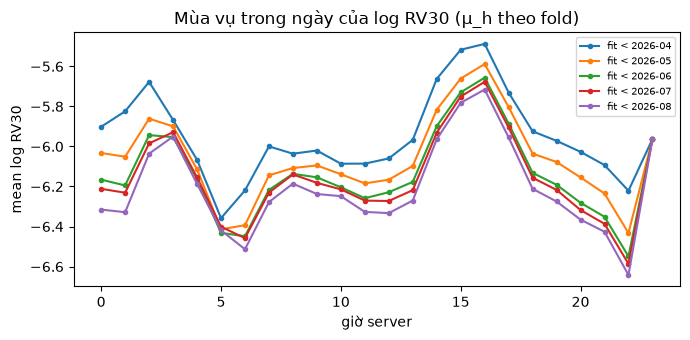

  [hình] reports/figures/g4_hour_profile.png

## B. KIỂM TRA CHỐNG NHÌN TƯƠNG LAI
  [OK] B1 nến dùng đã đóng: bar_time + 1 phút ≤ t (mọi dòng)  vi phạm = 0
  [OK] B2 nến dùng = floor(t) − 1 phút khi bar_age = 0  lag (phút) = [1.0]
  [OK] B3 cắt M1 tại 10 mốc ngẫu nhiên: đặc trưng nến ≤ mốc không đổi  max |chênh| = 0
  [OK] B4 nhiễu mọi nến ≥ floor(t), 20 sự kiện: đặc trưng tại t không đổi  bị đổi = 0
  [OK] B5 độ nhạy của B4: sự kiện kế tiếp (≥ t+3 phút) có đổi  20/20
  [OK] B6 mu_h, sigma_h không đổi khi nhiễu M1 từ tháng test trở đi (5 fold)  max |chênh| = 0

## C. LUẬN ĐIỂM DƯ THỪA: TREND vs NHỊP MỞ BẬC (plan 0.2)
Spearman trên tập chung (mọi tháng; dòng cùng basket phụ thuộc nhau, p-value chỉ tham khảo).
log_gap = log(1 + phút từ bậc trước); steps_60m = số bậc của basket mở trong 60 phút qua.
Kỳ vọng nếu dư thừa: ser60 càng âm khi bậc mở càng dày → rho(ser60, log_gap) > 0, rho(ser60, steps_60m) < 0.
     x            y  rho_all     p  rho_k2-4  rho_k5-9  rho_k>=10
 ser60      log_g

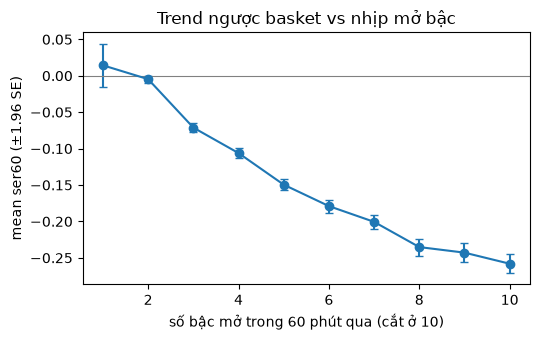

  [hình] reports/figures/g4_trend_vs_pace.png

## D. ABLATION BƯỚC 1 — PR-AUC GỘP OOS 04–08
OOS tập chung: 6,140 dòng | dương 1695 | prevalence 0.2761 | số ngày (cụm bootstrap) 100
Đối chiếu G1 (tập đầy đủ 6,160 dòng): PR-AUC log(k) = 0.4286 (G1 report: 0.4286)

[D1] PR-AUC gộp (CI 95% bootstrap theo ngày)
                model  n_feat     ap  ci_lo  ci_hi
            A0 log(k)       1 0.4266 0.3585 0.4850
              A1 họ 1       4 0.4212 0.3546 0.4796
        A2 họ 1 + vol       5 0.4208 0.3537 0.4792
A3 họ 1 + vol + trend       6 0.4496 0.3791 0.5113
      B1 log(k) + vol       2 0.4268 0.3595 0.4857
    B2 log(k) + trend       2 0.4566 0.3846 0.5184

[D2] ΔPR-AUC ghép cặp (CI 95% bootstrap theo ngày)
                                so_sanh   delta   ci_lo  ci_hi  P(delta>0)  CI_chua_0
                  A1 họ 1  −  A0 log(k) -0.0054 -0.0142 0.0035       0.131       True
              A2 họ 1 + vol  −  A1 họ 1 -0.0005 -0.0014 0.0004       0.169       True
A3 họ 1 + vol + trend  − 

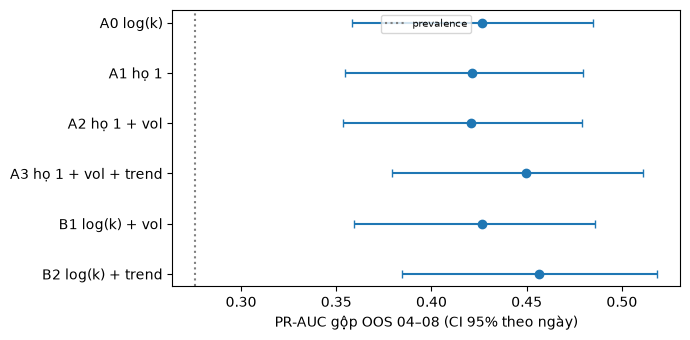

  [hình] reports/figures/g4_ablation.png

## E. PHÂN TẦNG THEO ĐỘ SÂU (A3 vs A0)
Trong mỗi nhóm k, A0 chỉ còn xếp hạng theo k trong nhóm; Δ đo phần tín hiệu M1 xếp hạng thêm.
   k    n  pos   prev  ap_A0  ap_A3  delta   ci_lo  ci_hi
 2-4 3606  684 0.1897 0.2286 0.2321 0.0035 -0.0102 0.0212
 5-9 1522  519 0.3410 0.3469 0.4052 0.0583  0.0255 0.0959
>=10 1012  492 0.4862 0.5509 0.6047 0.0538  0.0200 0.0980

## F. MÔ PHỎNG PHANH (ngưỡng chọn trên train) — CẬN TRÊN, KHÔNG PHẢI GIẢM LỖ
                model  target  brake_rate_rows  halted_pct  deep_caught  deep_caught_pct  avoided_total  avoided_pct  false_halts  false_halts_per100  false_flag_rows
            A0 log(k)     0.1            12.48        5.43           42            15.00            769        12.48           64                3.28              369
            A0 log(k)     0.2            24.09       12.25           81            28.93           1485        24.11          158                8.10              820
            A0

In [19]:
for d in (C.REPORTS, C.TABLES, C.FIGS):
    Path(d).mkdir(parents=True, exist_ok=True)
log = Tee(C.REPORTS / "g4_report.txt")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

log("G4 REPORT — Họ 2 (volatility), họ 3 (trend), ablation bước 1")
section(log, "0. MÔI TRƯỜNG VÀ THAM SỐ")
log(f"python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | sklearn {sklearn.__version__}")
log(f"RV_WIN={F.RV_WIN} | TREND_WIN={F.TREND_WIN} | offset=0 (G3) | n_boot={args.n_boot} | seed={C.SEED}")
log("Đại diện: họ 2 vol_z = log RV30 chuẩn hóa theo giờ server (mu_h, sigma_h fit trên M1 < tháng test);")
log("          họ 3 ser60 = efficiency ratio 60 phút có dấu theo chiều basket (<0 = ngược basket).")

samples = pd.read_parquet(args.samples)
m1 = pd.read_parquet(args.m1)
m1["time"] = m1["time"].astype("datetime64[ns]")
bars = F.bar_features(m1)


section(log, "A. ĐẶC TRƯNG VÀ DÒNG BỊ LOẠI")
feat = F.attach_features(samples, bars)
feat["steps_60m"] = F.steps_last_60m(feat)
n_all = len(feat)
no_bar = feat["m1_bar_age_min"] != 0
log(f"Dòng mẫu: {n_all:,} | nến liền trước không tồn tại (bar_age>0): {int(no_bar.sum())}")
for c in ("lrv30", "ser60", "ser30", "ret60_z"):
    log(f"  NaN {c:8s}: {int(feat[c].isna().sum())}")
drop = ~feat["m1_ok"]
pct = 100 * drop.mean()
log(f"Loại (thiếu M1 hoặc cửa sổ không liên tục): {int(drop.sum())} dòng = {pct:.2f}% "
    f"({'OK < 1%' if pct < 1 else '!! > 1%, xem lại'})")
log(f"  theo giờ server của t: {feat.loc[drop, 'timestamp'].dt.hour.value_counts().sort_index().to_dict()}")
log(f"  theo tháng: {feat.loc[drop, 'month'].value_counts().sort_index().to_dict()}")
log(f"  dương bị loại: {int(feat.loc[drop, 'y'].sum())}")
S = feat[feat["m1_ok"]].reset_index(drop=True)
log(f"Tập chung (mọi mô hình G4 đánh giá trên tập này): {len(S):,} dòng, dương {int(S['y'].sum())}")
log("\nPhân bố đặc trưng (tập chung):")
log(S[["lrv30", "ser60", "ser30", "ret60_z"]].describe(percentiles=[.05, .5, .95]).T.round(3).to_string())
log(f"Tỷ lệ ser60 < 0 (giá 60 phút qua đi ngược basket): {(S['ser60'] < 0).mean():.3f}")

norms = {m: F.fit_hour_norm(bars, pd.Timestamp(m + "-01")) for m in TEST_MONTHS}
prof = pd.DataFrame({m: n["mu"] for m, n in norms.items()})
prof.to_csv(C.TABLES / "g4_hour_norm_mu.csv")
nl = norms[TEST_MONTHS[-1]]
log(f"\nμ_h của log RV30 (fold test 08, fit 02–07): min giờ {int(nl['mu'].idxmin())} = {nl['mu'].min():.2f}, "
    f"max giờ {int(nl['mu'].idxmax())} = {nl['mu'].max():.2f}; "
    f"biên độ = {nl['mu'].max() - nl['mu'].min():.2f} log (≈ ×{np.exp(nl['mu'].max() - nl['mu'].min()):.1f} RV)")
log(f"Giờ có ít nến (n < 1000, fold 08): {nl.index[nl['n'] < 1000].tolist()}")
fig, ax = plt.subplots(figsize=(7, 3.5))
for m in TEST_MONTHS:
    ax.plot(prof.index, prof[m], marker=".", label=f"fit < {m}")
ax.set_xlabel("giờ server")
ax.set_ylabel("mean log RV30")
ax.set_title("Mùa vụ trong ngày của log RV30 (μ_h theo fold)")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(C.FIGS / "g4_hour_profile.png", dpi=130)
display(fig)
plt.close(fig)
log("  [hình] reports/figures/g4_hour_profile.png")

section(log, "B. KIỂM TRA CHỐNG NHÌN TƯƠNG LAI")
rng = np.random.default_rng(C.SEED)
checks = []
v = F.check_decision_bar(feat)
checks.append(("B1 nến dùng đã đóng: bar_time + 1 phút ≤ t (mọi dòng)", v == 0, f"vi phạm = {v}"))
age0 = feat.loc[~no_bar]
lag = (age0["timestamp"].dt.floor("min") - age0["m1_bar_time"]).dt.total_seconds().div(60)
checks.append(("B2 nến dùng = floor(t) − 1 phút khi bar_age = 0", bool((lag == 1).all()),
               f"lag (phút) = {sorted(lag.unique().tolist())[:5]}"))
cuts = pd.to_datetime(rng.choice(m1["time"].to_numpy()[5000:], 10, replace=False))
d = F.check_truncation(m1, cuts)
checks.append(("B3 cắt M1 tại 10 mốc ngẫu nhiên: đặc trưng nến ≤ mốc không đổi", d == 0, f"max |chênh| = {d:g}"))
idx = rng.choice(np.flatnonzero(feat["m1_ok"].to_numpy()), args.n_perturb, replace=False)
ch, sens = F.check_perturb_future(samples, m1, feat.index[idx], seed=C.SEED)
checks.append((f"B4 nhiễu mọi nến ≥ floor(t), {args.n_perturb} sự kiện: đặc trưng tại t không đổi",
               ch == 0, f"bị đổi = {ch}"))
checks.append(("B5 độ nhạy của B4: sự kiện kế tiếp (≥ t+3 phút) có đổi", sens > 0,
               f"{sens}/{args.n_perturb}"))
dn = max(F.check_norm_no_test(bars, pd.Timestamp(m + "-01"), seed=C.SEED) for m in TEST_MONTHS)
checks.append(("B6 mu_h, sigma_h không đổi khi nhiễu M1 từ tháng test trở đi (5 fold)", dn == 0, f"max |chênh| = {dn:g}"))
for name, ok, note in checks:
    log(f"  [{'OK' if ok else '!!'}] {name}  {note}")


section(log, "C. LUẬN ĐIỂM DƯ THỪA: TREND vs NHỊP MỞ BẬC (plan 0.2)")
log("Spearman trên tập chung (mọi tháng; dòng cùng basket phụ thuộc nhau, p-value chỉ tham khảo).")
log("log_gap = log(1 + phút từ bậc trước); steps_60m = số bậc của basket mở trong 60 phút qua.")
log("Kỳ vọng nếu dư thừa: ser60 càng âm khi bậc mở càng dày → rho(ser60, log_gap) > 0, rho(ser60, steps_60m) < 0.")
pairs = [("ser60", "log_gap"), ("ser60", "steps_60m"), ("ser60", "logk"), ("ser60", "log_since_r1"),
         ("vol_z*", "log_gap"), ("vol_z*", "steps_60m"), ("vol_z*", "logk"), ("ser60", "vol_z*")]
Sv = F.with_fold_vol(S, bars, TEST_MONTHS[-1])[0]          # vol_z* = chuẩn hóa fold 08 (chỉ để mô tả)
Sv["vol_z*"] = Sv["vol_z"]
rows = []
for a, b in pairs:
    r_all = stats.spearmanr(Sv[a], Sv[b])
    row = {"x": a, "y": b, "rho_all": r_all.statistic, "p": r_all.pvalue}
    for lo, hi, lab in K_BUCKETS:
        sub = Sv[(Sv["k"] >= lo) & (Sv["k"] <= hi)]
        row[f"rho_k{lab}"] = stats.spearmanr(sub[a], sub[b]).statistic
    rows.append(row)
red = pd.DataFrame(rows)
red.to_csv(C.TABLES / "g4_redundancy.csv", index=False)
log(red.round(3).to_string(index=False))
# R² khi hồi quy ser60 lên họ 1: đo phần thông tin trend đã có trong trạng thái basket
X = np.column_stack([np.ones(len(Sv)), Sv[F1].to_numpy()])
beta, *_ = np.linalg.lstsq(X, Sv["ser60"].to_numpy(), rcond=None)
r2 = 1 - np.var(Sv["ser60"].to_numpy() - X @ beta) / np.var(Sv["ser60"].to_numpy())
log(f"R² của OLS ser60 ~ họ 1 (logk, log_gap, accel, log_since_r1): {r2:.3f} "
    f"(phần biến thiên của trend đã giải thích bởi trạng thái basket)")
fig, ax = plt.subplots(figsize=(5.5, 3.5))
g = Sv.groupby(Sv["steps_60m"].clip(upper=10))["ser60"]
ax.errorbar(g.mean().index, g.mean(), yerr=1.96 * g.std() / np.sqrt(g.size()), marker="o", capsize=3)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("số bậc mở trong 60 phút qua (cắt ở 10)")
ax.set_ylabel("mean ser60 (±1.96 SE)")
ax.set_title("Trend ngược basket vs nhịp mở bậc")
fig.tight_layout()
fig.savefig(C.FIGS / "g4_trend_vs_pace.png", dpi=130)
display(fig)
plt.close(fig)
log("  [hình] reports/figures/g4_trend_vs_pace.png")

section(log, "D. ABLATION BƯỚC 1 — PR-AUC GỘP OOS 04–08")
oos = {name: F.walk_forward_m1(S, bars, TEST_MONTHS, feats) for name, feats in MODELS.items()}
ref = oos["A0 log(k)"]
for name, o in oos.items():
    assert (o["basket_id"].to_numpy() == ref["basket_id"].to_numpy()).all() and \
           (o["k"].to_numpy() == ref["k"].to_numpy()).all(), f"lệch thứ tự dòng: {name}"
full_g1 = walk_forward(samples, TEST_MONTHS, features=["logk"])
log(f"OOS tập chung: {len(ref):,} dòng | dương {int(ref['y'].sum())} | prevalence {ref['y'].mean():.4f} | "
    f"số ngày (cụm bootstrap) {ref['day'].nunique()}")
log(f"Đối chiếu G1 (tập đầy đủ {len(full_g1):,} dòng): PR-AUC log(k) = {pr_auc(full_g1['y'], full_g1['score']):.4f} "
    f"(G1 report: 0.4286)")

rows = []
for name, o in oos.items():
    bs = paired_bootstrap(o["y"], o["score"], ref["score"], o["day"], n_boot=args.n_boot)
    rows.append({"model": name, "n_feat": len(MODELS[name]), "ap": bs["ap_a"],
                 "ci_lo": bs["ci_a"][0], "ci_hi": bs["ci_a"][1]})
tab = pd.DataFrame(rows)
tab.to_csv(C.TABLES / "g4_ablation_ap.csv", index=False)
log("\n[D1] PR-AUC gộp (CI 95% bootstrap theo ngày)")
log(tab.round(4).to_string(index=False))

rows = []
for a, b in COMPARE:
    bs = paired_bootstrap(oos[a]["y"], oos[a]["score"], oos[b]["score"], oos[a]["day"], n_boot=args.n_boot)
    rows.append({"so_sanh": f"{a}  −  {b}", "delta": bs["delta"], "ci_lo": bs["ci_delta"][0],
                 "ci_hi": bs["ci_delta"][1], "P(delta>0)": bs["frac_delta_pos"],
                 "CI_chua_0": bs["ci_delta"][0] <= 0 <= bs["ci_delta"][1]})
dtab = pd.DataFrame(rows)
dtab.to_csv(C.TABLES / "g4_ablation_delta.csv", index=False)
log("\n[D2] ΔPR-AUC ghép cặp (CI 95% bootstrap theo ngày)")
log(dtab.round(4).to_string(index=False))

log("\n[D3] PR-AUC theo tháng (độ ổn định; mỗi tháng chỉ ~50–60 basket dương)")
bym = pd.DataFrame({name: o.groupby("month").apply(lambda d: pr_auc(d["y"], d["score"]), include_groups=False)
                    for name, o in oos.items()})
bym.insert(0, "prevalence", ref.groupby("month")["y"].mean())
bym.to_csv(C.TABLES / "g4_ablation_by_month.csv")
log(bym.round(4).to_string())
log(f"Số tháng A3 > A0: {int((bym['A3 họ 1 + vol + trend'] > bym['A0 log(k)']).sum())}/5")

fig, ax = plt.subplots(figsize=(7, 3.5))
yy = np.arange(len(tab))
ax.errorbar(tab["ap"], yy, xerr=[tab["ap"] - tab["ci_lo"], tab["ci_hi"] - tab["ap"]], fmt="o", capsize=3)
ax.axvline(ref["y"].mean(), color="grey", ls=":", label="prevalence")
ax.set_yticks(yy, tab["model"])
ax.invert_yaxis()
ax.set_xlabel("PR-AUC gộp OOS 04–08 (CI 95% theo ngày)")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(C.FIGS / "g4_ablation.png", dpi=130)
display(fig)
plt.close(fig)
log("  [hình] reports/figures/g4_ablation.png")


section(log, "E. PHÂN TẦNG THEO ĐỘ SÂU (A3 vs A0)")
rows = []
a3 = oos["A3 họ 1 + vol + trend"]
for lo, hi, lab in K_BUCKETS:
    m = ((ref["k"] >= lo) & (ref["k"] <= hi)).to_numpy()
    bs = paired_bootstrap(a3["y"][m], a3["score"][m], ref["score"][m], ref["day"][m], n_boot=args.n_boot)
    rows.append({"k": lab, "n": int(m.sum()), "pos": int(ref["y"][m].sum()), "prev": ref["y"][m].mean(),
                 "ap_A0": bs["ap_b"], "ap_A3": bs["ap_a"], "delta": bs["delta"],
                 "ci_lo": bs["ci_delta"][0], "ci_hi": bs["ci_delta"][1]})
st = pd.DataFrame(rows)
st.to_csv(C.TABLES / "g4_by_k.csv", index=False)
log("Trong mỗi nhóm k, A0 chỉ còn xếp hạng theo k trong nhóm; Δ đo phần tín hiệu M1 xếp hạng thêm.")
log(st.round(4).to_string(index=False))


section(log, "F. MÔ PHỎNG PHANH (ngưỡng chọn trên train) — CẬN TRÊN, KHÔNG PHẢI GIẢM LỖ")
rows = []
for name in ("A0 log(k)", "A1 họ 1", "A3 họ 1 + vol + trend"):
    o = oos[name]
    for q in C.BRAKE_RATES:
        r = brake_sim(o, o[f"thr_{round(q * 100)}"])
        rows.append({"model": name, "target": q, **r})
bt = pd.DataFrame(rows)
bt.to_csv(C.TABLES / "g4_brake.csv", index=False)
show = bt[["model", "target", "brake_rate_rows", "halted_pct", "deep_caught", "deep_caught_pct",
           "avoided_total", "avoided_pct", "false_halts", "false_halts_per100", "false_flag_rows"]].copy()
for c in ("brake_rate_rows", "halted_pct", "deep_caught_pct", "avoided_pct"):
    show[c] = 100 * show[c]
log(show.round(2).to_string(index=False))
log("Lưu ý: tỷ lệ phanh thực tế (brake_rate_rows) khác nhau giữa mô hình → so sánh công bằng nhất là")
log("đường cong bậc tránh được – phanh nhầm (G6). Dòng bị loại vì thiếu M1 coi như không có quyết định.")


section(log, "G. HỆ SỐ LOGISTIC CHUẨN HÓA (A3, từng fold)")
feats = MODELS["A3 họ 1 + vol + trend"]
coefs = {}
for m in TEST_MONTHS:
    Sm = F.with_fold_vol(S, bars, m)[0]
    tr, _, _ = make_fold(Sm, m)
    pipe = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000)).fit(tr[feats], tr["y"])
    coefs[m] = pd.Series(pipe[-1].coef_[0], index=feats)
ct = pd.DataFrame(coefs)
ct["mean"], ct["sign_stable"] = ct.mean(axis=1), (np.sign(ct[TEST_MONTHS]).nunique(axis=1) == 1)
ct.to_csv(C.TABLES / "g4_coef.csv")
log("(đơn vị: thay đổi log-odds khi đặc trưng tăng 1 SD trên train; ser60 < 0 = ngược basket)")
log(ct.round(3).to_string())


section(log, "H. ĐỘ NHẠY: CÁCH ĐO TREND (so với A2, không dùng để chọn mô hình)")
a2 = oos["A2 họ 1 + vol"]
rows = []
for name, fs in {"A3 ser60 (chính)": MODELS["A3 họ 1 + vol + trend"], **TREND_ALT}.items():
    o = F.walk_forward_m1(S, bars, TEST_MONTHS, fs)
    bs = paired_bootstrap(o["y"], o["score"], a2["score"], o["day"], n_boot=args.n_boot)
    rows.append({"model": name, "ap": bs["ap_a"], "delta_vs_A2": bs["delta"],
                 "ci_lo": bs["ci_delta"][0], "ci_hi": bs["ci_delta"][1]})
ht = pd.DataFrame(rows)
ht.to_csv(C.TABLES / "g4_trend_variants.csv", index=False)
log(ht.round(4).to_string(index=False))

section(log, "I. TIÊU CHÍ HOÀN THÀNH G4 (plan.md)")
crit = [
    ("Có vol (z theo giờ, fit trên train) và trend (ER có dấu)", True, ""),
    ("Dòng bị loại < 1%", pct < 1, f"{pct:.2f}%"),
    ("Có ΔPR-AUC kèm CI cho từng bước ablation", len(dtab) == len(COMPARE), f"{len(dtab)} so sánh"),
    ("Đã đo tương quan trend – nhịp mở bậc", True, "mục C"),
    ("Mọi kiểm tra chống nhìn tương lai đạt", all(ok for _, ok, _ in checks), "mục B"),
]
for name, ok, note in crit:
    log(f"  [{'OK' if ok else '!!'}] {name}  {note}")
feat.to_parquet(C.INTERIM / "g4_features.parquet", index=False)
log(f"\nĐã lưu {C.INTERIM / 'g4_features.parquet'} (đặc trưng thô; vol_z tính lại theo fold khi dùng)")
